## Sobre o dataset ICEWS

O **ICEWS (Integrated Crisis Early Warning System)** contém eventos
políticos codificados automaticamente a partir de notícias.

Cada registro representa uma interação na forma:

**Ator de origem → ação → ator de destino**

Os atores podem ser pessoas, governos, organizações e outros grupos.
As ações seguem a classificação **CAMEO (Conflict and Mediation
Event Observations)**, que inclui interações de cooperação e conflito.

Como os registros são extraídos de notícias por um sistema automático,
eles estão sujeitos a erros de extração, classificação e cobertura.
A ausência de um registro não significa necessariamente que um evento
não aconteceu.

### Fonte e obtenção

* **Repositório:** Harvard Dataverse.
* **Dataset:** ICEWS Coded Event Data.
* **DOI:** [10.7910/DVN/28075](https://doi.org/10.7910/DVN/28075).
* **Arquivos disponíveis localmente neste projeto:** eventos de 1995 a 2022.
* **Script de obtenção:** `data/dataset_parte2/baixar_icews.py`.

O script consulta a API do Harvard Dataverse para localizar os arquivos,
baixar os anos selecionados e extrair os arquivos compactados.
Os arquivos de eventos usam o formato tabular separado por tabulações
(TSV), com extensão `.tab`.

O intervalo disponível localmente não representa necessariamente
o intervalo carregado neste notebook.

### Dicionário resumido das colunas

| Coluna | Significado |
|---|---|
| `Event ID` | Identificador atribuído ao registro do evento. |
| `Event Date` | Data associada à ocorrência do evento. |
| `Source Name` | Nome do ator que realiza a ação. |
| `Source Sectors` | Setores ou classificações associados ao ator de origem. |
| `Source Country` | País associado ao ator de origem. |
| `Event Text` | Descrição da categoria da ação; não é o texto completo da notícia. |
| `CAMEO Code` | Código da categoria da ação na taxonomia CAMEO. |
| `Intensity` | Pontuação associada ao tipo de ação. |
| `Target Name` | Nome do ator destinatário da ação. |
| `Target Sectors` | Setores ou classificações associados ao ator de destino. |
| `Target Country` | País associado ao ator de destino. |
| `Story ID` | Identificador da notícia de origem. |
| `Sentence Number` | Número da sentença da notícia associada ao evento. |
| `Publisher` | Veículo responsável pela publicação da notícia. |
| `City` | Cidade associada à localização do evento. |
| `District` | Distrito associado à localização do evento. |
| `Province` | Estado, província ou divisão administrativa equivalente. |
| `Country` | País associado à localização do evento. |
| `Latitude` | Latitude da localização atribuída ao evento. |
| `Longitude` | Longitude da localização atribuída ao evento. |

`Source Country` e `Target Country` descrevem os países associados
aos atores. `Country` descreve a localização do evento; portanto,
essas colunas não precisam ter o mesmo valor.

Um ator pode possuir vários setores. Esses campos devem ser
inspecionados antes de serem tratados como uma única categoria.

### Valores ausentes

O pandas representa valores ausentes por marcadores como `NaN`,
`NaT` e `pd.NA`, dependendo do tipo da coluna.

É necessário distinguir:

* Campos realmente vazios no arquivo original.
* Textos que o pandas interpreta como valores ausentes durante a leitura.
* Valores cuja informação não foi identificada ou disponibilizada.

A presença de um nulo, isoladamente, não revela o motivo da ausência.
Por exemplo, um `District` vazio não significa que o evento inteiro
esteja sem localização: outras colunas geográficas podem estar preenchidas.

As regras específicas de preenchimento devem ser verificadas no
manual oficial e comparadas com os arquivos brutos.

Para a análise exploratória:

* Calcular a quantidade e o percentual de nulos por coluna.
* Inspecionar exemplos dos registros com informação ausente.
* Avaliar quais campos são necessários para cada análise.
* Evitar excluir todas as linhas com algum nulo sem avaliar a perda de dados.
* Evitar preencher indiscriminadamente os nulos com zero.

Zero pode ser um valor válido em coordenadas e pontuações.
Preencher ausências com zero pode, portanto, alterar o significado dos dados.

### Tipos de dados e estatísticas descritivas

Uma coluna armazenada como número não é necessariamente uma medida
quantitativa.

* `Event ID` e `Story ID` são identificadores.
* `CAMEO Code` é um código de classificação, não uma quantidade.
* `Sentence Number` indica uma posição na notícia.
* `Intensity`, `Latitude` e `Longitude` possuem interpretação quantitativa,
  mas exigem análises compatíveis com seu significado.

Médias e desvios de identificadores ou códigos CAMEO normalmente não
possuem interpretação útil. Por isso, as colunas usadas no `describe()`
devem ser selecionadas conforme o objetivo da análise.

Os códigos CAMEO devem ser tratados como categorias. Na leitura dos
arquivos, é recomendável preservá-los como texto para manter possíveis
zeros à esquerda.

Também é necessário verificar duplicatas antes de assumir que
`Event ID` identifica sozinho cada registro, especialmente ao combinar
arquivos de diferentes anos.

### Documentação oficial

1. **[ICEWS Coded Event Data Read Me](https://dataverse.harvard.edu/api/access/datafile/2548466)**  
   Referência inicial para o formato dos dados, definição dos campos
   e observações gerais de uso.

2. **[ICEWS Events and Aggregations](https://dataverse.harvard.edu/api/access/datafile/2548486)**  
   Explica os conceitos relacionados aos eventos e às agregações.
   A seção 1 apresenta conceitos básicos, e o apêndice F contém um glossário.

3. **[CAMEO Codebook, versão 0.9b5](https://dataverse.harvard.edu/api/access/datafile/2509776)**  
   Apresenta a taxonomia usada para classificar as ações.
   É a referência para interpretar a coluna `CAMEO Code`.

4. **[ICEWS Expanded CAMEO Annotation Guidelines](https://dataverse.harvard.edu/api/access/datafile/2531993)**  
   Complementa o CAMEO Codebook com regras e exemplos mais específicos
   sobre a classificação dos eventos.

5. **[BBN ACCENT Event Coding Evaluation](https://dataverse.harvard.edu/api/access/datafile/2711073)**  
   Descreve a avaliação do sistema automático responsável pela codificação,
   incluindo aspectos de qualidade, recuperação de eventos e tradução automática.

Os links apontam para os PDFs disponibilizados pelo Harvard Dataverse.
Este resumo é introdutório; decisões específicas sobre códigos,
pontuações e valores ausentes devem seguir os manuais oficiais.

### Referência bibliográfica

Boschee, E.; Lautenschlager, J.; O'Brien, S.; Shellman, S.;
Starz, J.; Ward, M. (2015).
*ICEWS Coded Event Data*. Harvard Dataverse.
https://doi.org/10.7910/DVN/28075

Para reprodutibilidade, registrar também a versão do dataset,
a data do download e os arquivos efetivamente utilizados na análise.

## Referências dos códigos e classificações

### Códigos e famílias CAMEO

`CAMEO Code` identifica a categoria da ação e `Event Text` apresenta sua descrição em inglês. Os dois primeiros caracteres identificam a família geral; os demais detalham a ação. Por exemplo, `07` representa ajuda, `070` representa ajuda sem especificação e `073` representa ajuda humanitária. Preservo os códigos como texto para manter os zeros iniciais.

A tabela abaixo traduz de forma resumida as 20 famílias do [CAMEO Codebook 0.9b5, capítulo 1](https://eventdata.parusanalytics.com/cameo.dir/CAMEO.CDB.09b5.pdf). Consulto as regras específicas do ICEWS nas [Expanded CAMEO Annotation Guidelines](https://dataverse.harvard.edu/api/access/datafile/2531993).

| Família | Significado |
|:---|:---|
| `01` | Declarações públicas |
| `02` | Apelos e pedidos |
| `03` | Intenção de cooperar |
| `04` | Consultas e negociações |
| `05` | Cooperação diplomática |
| `06` | Cooperação material |
| `07` | Fornecimento de ajuda |
| `08` | Concessões |
| `09` | Investigação |
| `10` | Exigências |
| `11` | Desaprovação |
| `12` | Rejeição |
| `13` | Ameaças |
| `14` | Protestos |
| `15` | Demonstração de força militar ou policial |
| `16` | Redução de relações |
| `17` | Coerção |
| `18` | Agressões |
| `19` | Combate |
| `20` | Violência em massa não convencional |

### Códigos presentes em 1995

A tabela contém os 241 códigos encontrados em `raw/eventos_1995.tab`, com o rótulo original, uma tradução explicativa e a intensidade observada no arquivo. A tradução serve de apoio à leitura e não substitui a definição oficial. A pontuação não representa número de vítimas ou danos.

Esta é uma referência de 1995, não um catálogo completo de todos os anos. Outros recortes podem incluir códigos adicionais, que precisam ser consultados nos manuais. Um registro codificado como determinada ação informa a classificação extraída da notícia; não comprova, sozinho, a ocorrência real dessa ação.

<details>
<summary>Abrir a tabela dos 241 códigos</summary>

| Código | Descrição no arquivo | Significado em português | Intensidade observada |
|:---|:---|:---|---:|
| `010` | Make statement | Fazer uma declaração | 0 |
| `011` | Decline comment | Recusar comentar | -0.1 |
| `012` | Make pessimistic comment | Fazer um comentário pessimista | -0.4 |
| `013` | Make optimistic comment | Fazer um comentário otimista | 0.4 |
| `014` | Consider policy option | Considerar uma opção de política | 0 |
| `015` | Acknowledge or claim responsibility | Reconhecer ou assumir responsabilidade | 0 |
| `016` | Deny responsibility | Negar responsabilidade | -5 |
| `017` | Engage in symbolic act | Realizar um ato simbólico | 0 |
| `018` | Make empathetic comment | Fazer um comentário de empatia | 3.4 |
| `019` | Express accord | Expressar concordância | 3.4 |
| `020` | Make an appeal or request | Fazer um apelo ou pedido | 3 |
| `021` | Appeal for material cooperation | Solicitar cooperação material | 3.4 |
| `0211` | Appeal for economic cooperation | Solicitar cooperação econômica | 3.4 |
| `0212` | Appeal for military cooperation | Solicitar cooperação militar | 3.4 |
| `0213` | Appeal for judicial cooperation | Solicitar cooperação judicial | 3.4 |
| `0214` | Appeal for intelligence | Solicitar cooperação de inteligência | 3.4 |
| `022` | Appeal for diplomatic cooperation (such as policy support) | Solicitar cooperação diplomática | 3.4 |
| `023` | Appeal for aid | Solicitar ajuda | 3.4 |
| `0231` | Appeal for economic aid | Solicitar ajuda econômica | 3.4 |
| `0232` | Appeal for military aid | Solicitar ajuda militar | 3.4 |
| `0233` | Appeal for humanitarian aid | Solicitar ajuda humanitária | 3.4 |
| `0234` | Appeal for military protection or peacekeeping | Solicitar proteção militar ou manutenção da paz | 3.4 |
| `024` | Appeal for political reform | Solicitar reforma política | -0.3 |
| `0241` | Appeal for change in leadership | Solicitar mudança de liderança | -0.3 |
| `0242` | Appeal for policy change | Solicitar mudança de política | -0.3 |
| `0243` | Appeal for rights | Solicitar direitos | -0.3 |
| `0244` | Appeal for change in institutions, regime | Solicitar mudança nas instituições ou no regime | -0.3 |
| `025` | Appeal to yield | Solicitar que o destinatário ceda | -0.3 |
| `0251` | Appeal for easing of administrative sanctions | Solicitar alívio de sanções administrativas | -0.3 |
| `0252` | Appeal for easing of political dissent | Solicitar redução da dissidência política | -0.3 |
| `0253` | Appeal for release of persons or property | Solicitar libertação de pessoas ou devolução de bens | -0.3 |
| `0254` | Appeal for easing of economic sanctions, boycott, or embargo | Solicitar alívio de sanções econômicas, boicote ou embargo | -0.3 |
| `0256` | Appeal for de-escalation of military engagement | Solicitar redução do envolvimento militar | -0.3 |
| `026` | Appeal to others to meet or negotiate | Solicitar reunião ou negociação | 4 |
| `027` | Appeal to others to settle dispute | Solicitar resolução de uma disputa | 4 |
| `028` | Appeal to engage in or accept mediation | Solicitar participação em mediação ou sua aceitação | 4 |
| `030` | Express intent to cooperate | Expressar intenção de cooperar | 4 |
| `031` | Express intent to engage in material cooperation | Expressar intenção de cooperação material | 5.2 |
| `0311` | Express intent to cooperate economically | Expressar intenção de cooperação econômica | 5.2 |
| `0312` | Express intent to cooperate militarily | Expressar intenção de cooperação militar | 5.2 |
| `0313` | Express intent to cooperate on judicial matters | Expressar intenção de cooperação judicial | 5.2 |
| `0314` | Express intent to cooperate on intelligence | Expressar intenção de cooperação de inteligência | 5.2 |
| `032` | Express intent to engage in diplomatic cooperation (such as policy support) | Expressar intenção de cooperação diplomática | 4.5 |
| `033` | Express intent to provide material aid | Expressar intenção de fornecer ajuda material | 5.2 |
| `0331` | Express intent to provide economic aid | Expressar intenção de fornecer ajuda econômica | 5.2 |
| `0332` | Express intent to provide military aid | Expressar intenção de fornecer ajuda militar | 5.2 |
| `0333` | Express intent to provide humanitarian aid | Expressar intenção de fornecer ajuda humanitária | 5.2 |
| `0334` | Express intent to provide military protection or peacekeeping | Expressar intenção de fornecer proteção militar ou manutenção da paz | 6 |
| `034` | Express intent to institute political reform | Expressar intenção de instituir reforma política | 7 |
| `0341` | Express intent to change leadership | Expressar intenção de mudar a liderança | 7 |
| `0342` | Express intent to change policy | Expressar intenção de mudar a política | 7 |
| `0344` | Express intent to change institutions, regime | Expressar intenção de mudar as instituições ou o regime | 7 |
| `035` | Express intent to yield | Expressar intenção de ceder | 7 |
| `0351` | Express intent to ease administrative sanctions | Expressar intenção de aliviar sanções administrativas | 7 |
| `0353` | Express intent to release persons or property | Expressar intenção de libertar pessoas ou devolver bens | 7 |
| `0354` | Express intent to ease economic sanctions, boycott, or embargo | Expressar intenção de aliviar sanções econômicas, boicote ou embargo | 7 |
| `0356` | Express intent to de-escalate military engagement | Expressar intenção de reduzir o envolvimento militar | 7 |
| `036` | Express intent to meet or negotiate | Expressar intenção de reunir ou negociar | 4 |
| `037` | Express intent to settle dispute | Expressar intenção de resolver uma disputa | 5 |
| `038` | Express intent to accept mediation | Expressar intenção de aceitar mediação | 7 |
| `039` | Express intent to mediate | Expressar intenção de mediar | 5 |
| `040` | Consult | Consultar | 1 |
| `041` | Discuss by telephone | Conversar por telefone | 1 |
| `042` | Make a visit | Realizar uma visita | 1.9 |
| `043` | Host a visit | Receber uma visita | 2.8 |
| `044` | Meet at a 'third' location | Reunir em um terceiro local | 2.5 |
| `045` | Mediate | Mediar | 5 |
| `046` | Engage in negotiation | Participar de negociação | 7 |
| `050` | Engage in diplomatic cooperation | Realizar cooperação diplomática | 3.5 |
| `051` | Praise or endorse | Elogiar ou apoiar | 3.4 |
| `052` | Defend verbally | Defender verbalmente | 3.5 |
| `053` | Rally support on behalf of | Mobilizar apoio em favor de alguém | 3.8 |
| `054` | Grant diplomatic recognition | Conceder reconhecimento diplomático | 6 |
| `055` | Apologize | Pedir desculpas | 7 |
| `056` | Forgive | Perdoar | 7 |
| `057` | Sign formal agreement | Assinar um acordo formal | 8 |
| `060` | Engage in material cooperation | Realizar cooperação material | 6 |
| `061` | Cooperate economically | Cooperar economicamente | 6.4 |
| `062` | Cooperate militarily | Cooperar militarmente | 7.4 |
| `063` | Engage in judicial cooperation | Cooperar em assuntos judiciais | 7.4 |
| `064` | Share intelligence or information | Compartilhar informações ou inteligência | 7 |
| `070` | Provide aid | Fornecer ajuda | 7 |
| `071` | Provide economic aid | Fornecer ajuda econômica | 7.4 |
| `072` | Provide military aid | Fornecer ajuda militar | 8.3 |
| `073` | Provide humanitarian aid | Fornecer ajuda humanitária | 7.4 |
| `074` | Provide military protection or peacekeeping | Fornecer proteção militar ou manutenção da paz | 8.5 |
| `075` | Grant asylum | Conceder asilo | 7 |
| `080` | Yield | Ceder | 5 |
| `081` | Ease administrative sanctions | Aliviar sanções administrativas | 5 |
| `0811` | Ease restrictions on political freedoms | Aliviar restrições às liberdades políticas | 5 |
| `0812` | Ease ban on political parties or politicians | Aliviar proibição de partidos ou políticos | 5 |
| `0813` | Ease curfew | Aliviar toque de recolher | 5 |
| `0814` | Ease state of emergency or martial law | Aliviar estado de emergência ou lei marcial | 5 |
| `082` | Ease political dissent | Reduzir a dissidência política | 5 |
| `083` | Accede to requests or demands for political reform | Atender a pedidos ou exigências de reforma política | 5 |
| `0831` | Accede to demands for change in leadership | Atender a exigências de mudança de liderança | 5 |
| `0832` | Accede to demands for change in policy | Atender a exigências de mudança de política | 5 |
| `0833` | Accede to demands for rights | Atender a exigências de concessão de direitos | 5 |
| `0834` | Accede to demands for change in institutions, regime | Atender a exigências de mudança nas instituições ou no regime | 5 |
| `0841` | Return, release person(s) | Libertar ou devolver pessoas | 7 |
| `0842` | Return, release property | Devolver bens | 7 |
| `085` | Ease economic sanctions, boycott, embargo | Aliviar sanções econômicas, boicote ou embargo | 7 |
| `0861` | Receive deployment of peacekeepers | Receber forças de manutenção da paz | 9 |
| `0862` | Receive inspectors | Receber inspetores | 9 |
| `0871` | Declare truce, ceasefire | Declarar trégua ou cessar fogo | 9 |
| `0872` | Ease military blockade | Aliviar bloqueio militar | 9 |
| `0873` | Demobilize armed forces | Desmobilizar as forças armadas | 9 |
| `0874` | Retreat or surrender militarily | Recuar ou render militarmente | 10 |
| `090` | Investigate | Investigar | -2 |
| `091` | Investigate crime, corruption | Investigar crime ou corrupção | -2 |
| `092` | Investigate human rights abuses | Investigar violações de direitos humanos | -2 |
| `094` | Investigate war crimes | Investigar crimes de guerra | -2 |
| `100` | Demand | Exigir | -5 |
| `101` | Demand material cooperation | Exigir cooperação material | -5 |
| `1011` | Demand economic cooperation | Exigir cooperação econômica | -5 |
| `1013` | Demand judicial cooperation | Exigir cooperação judicial | -5 |
| `1014` | Demand intelligence cooperation | Exigir cooperação de inteligência | -5 |
| `102` | Demand diplomatic cooperation (such as policy support) | Exigir cooperação diplomática | -5 |
| `103` | Demand material aid | Exigir ajuda material | -5 |
| `1031` | Demand economic aid | Exigir ajuda econômica | -5 |
| `1032` | Demand military aid | Exigir ajuda militar | -5 |
| `104` | Demand political reform | Exigir reforma política | -5 |
| `1041` | Demand change in leadership | Exigir mudança de liderança | -5 |
| `1042` | Demand policy change | Exigir mudança de política | -5 |
| `1043` | Demand rights | Exigir direitos | -5 |
| `1044` | Demand change in institutions, regime | Exigir mudança nas instituições ou no regime | -5 |
| `105` | Demand that target yields | Exigir que o destinatário ceda | -5 |
| `1051` | Demand easing of administrative sanctions | Exigir alívio de sanções administrativas | -5 |
| `1052` | Demand easing of political dissent | Exigir redução da dissidência política | -5 |
| `1053` | Demand release of persons or property | Exigir libertação de pessoas ou devolução de bens | -5 |
| `1054` | Demand easing of economic sanctions, boycott, or embargo | Exigir alívio de sanções econômicas, boicote ou embargo | -5 |
| `1056` | Demand de-escalation of military engagement | Exigir redução do envolvimento militar | -5 |
| `106` | Demand meeting, negotiation | Exigir reunião ou negociação | -5 |
| `107` | Demand settling of dispute | Exigir resolução de uma disputa | -5 |
| `108` | Demand mediation | Exigir mediação | -5 |
| `111` | Criticize or denounce | Criticar ou condenar | -2 |
| `112` | Accuse | Acusar | -2 |
| `1121` | Accuse of crime, corruption | Acusar de crime ou corrupção | -2 |
| `1122` | Accuse of human rights abuses | Acusar de violações de direitos humanos | -2 |
| `1123` | Accuse of aggression | Acusar de agressão | -2 |
| `1124` | Accuse of war crimes | Acusar de crimes de guerra | -2 |
| `1125` | Accuse of espionage, treason | Acusar de espionagem ou traição | -2 |
| `113` | Rally opposition against | Mobilizar oposição contra alguém | -2 |
| `114` | Complain officially | Reclamar oficialmente | -2 |
| `115` | Bring lawsuit against | Mover uma ação judicial contra alguém | -2 |
| `120` | Reject | Rejeitar | -4 |
| `121` | Reject material cooperation | Rejeitar cooperação material | -4 |
| `1211` | Reject economic cooperation | Rejeitar cooperação econômica | -4 |
| `1212` | Reject military cooperation | Rejeitar cooperação militar | -4 |
| `1213` | Reject judicial cooperation | Rejeitar cooperação judicial | -4 |
| `122` | Reject request or demand for material aid | Rejeitar pedido ou exigência de ajuda material | -4 |
| `1221` | Reject request for economic aid | Rejeitar pedido de ajuda econômica | -4 |
| `1222` | Reject request for military aid | Rejeitar pedido de ajuda militar | -4 |
| `1223` | Reject request for humanitarian aid | Rejeitar pedido de ajuda humanitária | -4 |
| `1224` | Reject request for military protection or peacekeeping | Rejeitar pedido de proteção militar ou manutenção da paz | -4 |
| `123` | Reject request or demand for political reform | Rejeitar pedido ou exigência de reforma política | -4 |
| `1231` | Reject request for change in leadership | Rejeitar pedido de mudança de liderança | -4 |
| `124` | Refuse to yield | Recusar ceder | -4 |
| `1241` | Refuse to ease administrative sanctions | Recusar aliviar sanções administrativas | -4 |
| `1243` | Refuse to release persons or property | Recusar libertar pessoas ou devolver bens | -4 |
| `1244` | Refuse to ease economic sanctions, boycott, or embargo | Recusar aliviar sanções econômicas, boicote ou embargo | -4 |
| `1246` | Refuse to de-escalate military engagement | Recusar reduzir o envolvimento militar | -4 |
| `125` | Reject proposal to meet, discuss, or negotiate | Rejeitar proposta de reunião, discussão ou negociação | -5 |
| `126` | Reject mediation | Rejeitar mediação | -5 |
| `127` | Reject plan, agreement to settle dispute | Rejeitar plano ou acordo para resolver uma disputa | -5 |
| `128` | Defy norms, law | Desafiar normas ou leis | -5 |
| `129` | Veto | Vetar | -5 |
| `130` | Threaten | Ameaçar | -4.4 |
| `131` | Threaten non-force | Ameaçar com medidas sem uso da força | -5.8 |
| `1311` | Threaten to reduce or stop aid | Ameaçar reduzir ou interromper ajuda | -5.8 |
| `1312` | Threaten with sanctions, boycott, embargo | Ameaçar aplicar sanções, boicote ou embargo | -5.8 |
| `1313` | Threaten to reduce or break relations | Ameaçar reduzir ou romper relações | -5.8 |
| `132` | Threaten with administrative sanctions | Ameaçar aplicar sanções administrativas | -5.8 |
| `1321` | Threaten with restrictions on political freedoms | Ameaçar restringir liberdades políticas | -5.8 |
| `1322` | Threaten to ban political parties or politicians | Ameaçar proibir partidos ou políticos | -5.8 |
| `133` | Threaten with political dissent, protest | Ameaçar realizar dissidência política ou protesto | -5.8 |
| `134` | Threaten to halt negotiations | Ameaçar interromper negociações | -5.8 |
| `137` | Threaten with repression | Ameaçar reprimir | -7 |
| `138` | Threaten with military force | Ameaçar usar força militar | -7 |
| `139` | Give ultimatum | Emitir um ultimato | -7 |
| `141` | Demonstrate or rally | Realizar manifestação ou ato público | -6.5 |
| `1411` | Demonstrate for leadership change | Manifestar por mudança de liderança | -6.5 |
| `1412` | Demonstrate for policy change | Manifestar por mudança de política | -6.5 |
| `142` | Conduct hunger strike | Realizar greve de fome | -6.5 |
| `143` | Conduct strike or boycott | Realizar greve ou boicote | -6.5 |
| `1431` | Conduct strike or boycott for leadership change | Realizar greve ou boicote por mudança de liderança | -6.5 |
| `1432` | Conduct strike or boycott for policy change | Realizar greve ou boicote por mudança de política | -6.5 |
| `144` | Obstruct passage, block | Obstruir ou bloquear passagem | -7.5 |
| `145` | Protest violently, riot | Realizar protesto violento ou tumulto | -7.5 |
| `1452` | Engage in violent protest for policy change | Realizar protesto violento por mudança de política | -7.5 |
| `150` | Demonstrate military or police power | Demonstrar poder militar ou policial | -7.2 |
| `151` | Increase police alert status | Elevar o estado de alerta policial | -7.2 |
| `152` | Increase military alert status | Elevar o estado de alerta militar | -7.2 |
| `153` | Mobilize or increase police power | Mobilizar ou ampliar a força policial | -7.2 |
| `154` | Mobilize or increase armed forces | Mobilizar ou ampliar as forças armadas | -7.2 |
| `160` | Reduce relations | Reduzir relações | -4 |
| `161` | Reduce or break diplomatic relations | Reduzir ou romper relações diplomáticas | -4 |
| `162` | Reduce or stop material aid | Reduzir ou interromper ajuda material | -5.6 |
| `1621` | Reduce or stop economic assistance | Reduzir ou interromper ajuda econômica | -5.6 |
| `1622` | Reduce or stop military assistance | Reduzir ou interromper ajuda militar | -5.6 |
| `1623` | Reduce or stop humanitarian assistance | Reduzir ou interromper ajuda humanitária | -5.6 |
| `163` | Impose embargo, boycott, or sanctions | Impor embargo, boicote ou sanções | -8 |
| `164` | Halt negotiations | Interromper negociações | -6.5 |
| `165` | Halt mediation | Interromper mediação | -7 |
| `166` | Expel or withdraw | Expulsar ou retirar | -7 |
| `1661` | Expel or withdraw peacekeepers | Expulsar ou retirar forças de manutenção da paz | -7 |
| `170` | Coerce | Coagir | -7 |
| `171` | Seize or damage property | Apreender ou danificar bens | -9.2 |
| `1711` | Confiscate property | Confiscar bens | -9.2 |
| `1712` | Destroy property | Destruir bens | -9.2 |
| `172` | Impose administrative sanctions | Impor sanções administrativas | -5 |
| `1721` | Impose restrictions on political freedoms | Restringir liberdades políticas | -5 |
| `1722` | Ban political parties or politicians | Proibir partidos ou políticos | -5 |
| `1723` | Impose curfew | Impor toque de recolher | -5 |
| `1724` | Impose state of emergency or martial law | Impor estado de emergência ou lei marcial | -5 |
| `173` | Arrest, detain, or charge with legal action | Prender, deter ou apresentar acusação judicial | -5 |
| `174` | Expel or deport individuals | Expulsar ou deportar pessoas | -5 |
| `175` | Use tactics of violent repression | Empregar repressão violenta | -9 |
| `180` | Use unconventional violence | Empregar violência não convencional | -9 |
| `181` | Abduct, hijack, or take hostage | Sequestrar ou fazer reféns | -9 |
| `182` | Physically assault | Agredir fisicamente | -9.5 |
| `1821` | Sexually assault | Praticar violência sexual | -9 |
| `1822` | Torture | Torturar | -9 |
| `1823` | Kill by physical assault | Matar por agressão física | -10 |
| `183` | Conduct suicide, car, or other non-military bombing | Realizar atentado suicida, com carro bomba ou outro ataque a bomba não militar | -10 |
| `1831` | Carry out suicide bombing | Realizar atentado suicida a bomba | -10 |
| `184` | Use as human shield | Usar como escudo humano | -8 |
| `185` | Attempt to assassinate | Tentar assassinar | -8 |
| `186` | Assassinate | Assassinar | -10 |
| `190` | Use conventional military force | Empregar força militar convencional | -10 |
| `191` | Impose blockade, restrict movement | Impor bloqueio ou restringir movimento | -9.5 |
| `192` | Occupy territory | Ocupar território | -9.5 |
| `193` | fight with small arms and light weapons | Combater com armas pequenas e leves | -10 |
| `194` | fight with artillery and tanks | Combater com artilharia e tanques | -10 |
| `195` | Employ aerial weapons | Empregar armamentos aéreos | -10 |
| `196` | Violate ceasefire | Violar cessar fogo | -9.5 |
| `201` | Engage in mass expulsion | Realizar expulsão em massa | -9.5 |
| `202` | Engage in mass killings | Realizar assassinatos em massa | -10 |
| `203` | Engage in ethnic cleansing | Realizar limpeza étnica | -10 |
| `2041` | Use chemical, biological, or radiological weapons | Usar armas químicas, biológicas ou radiológicas | -10 |
| `2042` | Detonate nuclear weapons | Detonar armas nucleares | -10 |

</details>

### Identificadores e posição na notícia

| Campo | Significado |
|:---|:---|
| `Event ID` | Identificador atribuído ao registro. Não é uma classificação da ação, e sua unicidade deve ser verificada. |
| `Story ID` | Identificador da notícia de origem. Uma mesma notícia pode estar associada a vários registros. |
| `Sentence Number` | Posição da sentença na notícia. O valor `5`, por exemplo, indica a quinta sentença. |
| `arquivo_origem` | Nome do arquivo de onde veio o registro. Acrescento essa coluna para manter a procedência. |

Esses campos não têm uma tabela de categorias equivalente à do CAMEO. As definições devem ser conferidas no [ICEWS Coded Event Data Read Me](https://dataverse.harvard.edu/api/access/datafile/2548466).

### Classificações dos atores e siglas

`Source Sectors` e `Target Sectors` contêm rótulos de classificação, e um ator pode ter vários ao mesmo tempo. Os exemplos abaixo ajudam a ler esses campos sem apresentar uma lista exaustiva de setores, grupos étnicos ou religiosos.

| Rótulo ou sigla | Significado para leitura |
|:---|:---|
| `Government` | Governo |
| `Executive` | Poder Executivo |
| `Executive Office` | Gabinete ou órgão da chefia do Executivo |
| `Legislative / Parliamentary` | Poder Legislativo ou parlamento |
| `Judicial` | Poder Judiciário |
| `Military` | Forças militares |
| `Police` | Polícia |
| `General Population / Civilian / Social` | População em geral, civis ou grupos sociais |
| `Dissident` | Dissidente ou ator de oposição |
| `Rebel` | Rebelde |
| `Insurgents` | Insurgentes |
| `Radicals / Extremists / Fundamentalists` | Radicais, extremistas ou fundamentalistas, conforme a classificação da fonte |
| `Business` | Empresas ou setor empresarial |
| `Media` | Meios de comunicação |
| `Refugees / Displaced` | Refugiados ou pessoas deslocadas |
| `IGOs` | Organizações intergovernamentais |
| `NGOs` | Organizações não governamentais |
| `MNCs` | Empresas multinacionais |

Essas traduções explicam os rótulos presentes no arquivo. Não atribuo novos códigos aos atores nem aplico automaticamente códigos de atores de outros formatos CAMEO.

### Termos usados nos resultados

| Termo | Significado |
|:---|:---|
| `Intensity` | Pontuação associada à ação; a tabela de consulta mostra o valor observado em 1995. |
| `familia_cameo` | Coluna criada na EDA com os dois primeiros caracteres de `CAMEO Code`. |
| `mes` | Coluna criada com o mês e o ano de `Event Date`. |
| `peso` | Quantidade de registros agrupados para um mesmo par de atores e mês. |
| `True` | Verdadeiro. Com `isna()`, indica que o campo está ausente. |
| `False` | Falso. Com `isna()`, indica que o campo está preenchido. |

Os países em `Source Country`, `Target Country` e `Country` já aparecem como nomes. Origem é quem realiza a ação e destino é quem recebe ou é alvo dela. O código CAMEO permite interpretar se a interação representa ajuda, crítica, ameaça, ataque ou outro tipo de ação.


## Bibliotecas

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

## Leitura dos dados

In [2]:
pasta = Path("raw")

if not pasta.exists():
    pasta = Path("data/dataset_parte2/raw")

anos = [1995]

In [3]:
tabelas = []

for ano in anos:
    arquivo = pasta / f"eventos_{ano}.tab"

    tabela = pd.read_csv(
        arquivo,
        sep="\t",
        dtype="string",
        keep_default_na=False,
        na_values=[""],
    )

    tabela["arquivo_origem"] = arquivo.name
    tabelas.append(tabela)

df_bruto = pd.concat(tabelas, ignore_index=True)
colunas_originais = df_bruto.columns.drop("arquivo_origem").tolist()

del tabelas, tabela

df_bruto.head()

,Event ID,Event Date,Source Name,Source Sectors,Source Country,Event Text,CAMEO Code,Intensity,Target Name,Target Sectors,...,Story ID,Sentence Number,Publisher,City,District,Province,Country,Latitude,Longitude,arquivo_origem
0,926685,1995-01-01,Extremist (Russia),"Radicals / Extremists / Fundamentalists,Dissident",Russian Federation,Praise or endorse,051,3.4,Boris Yeltsin,"Elite,Executive,Executive Office,Government",...,28235806,5,The Toronto Star,Moscow,<NA>,Moskva,Russian Federation,55.7522,37.6156,eventos_1995.tab
1,926687,1995-01-01,Government (Bosnia and Herzegovina),Government,Bosnia and Herzegovina,Express intent to cooperate,030,4,Citizen (Serbia),"General Population / Civilian / Social,Social",...,28235807,1,The Toronto Star,<NA>,<NA>,Bosnia,Bosnia and Herzegovina,44,18,eventos_1995.tab
2,926686,1995-01-01,Citizen (Serbia),"General Population / Civilian / Social,Social",Serbia,Express intent to cooperate,030,4,Government (Bosnia and Herzegovina),Government,...,28235807,1,The Toronto Star,<NA>,<NA>,Bosnia,Bosnia and Herzegovina,44,18,eventos_1995.tab
3,926688,1995-01-01,Canada,<NA>,Canada,Praise or endorse,051,3.4,City Mayor (Canada),"Government,Local,Municipal",...,28235809,3,The Toronto Star,<NA>,<NA>,Ontario,Canada,49.2501,-84.4998,eventos_1995.tab
4,926689,1995-01-01,Lawyer/Attorney (Canada),"Legal,Social",Canada,"Arrest, detain, or charge with legal action",173,-5,Police (Canada),"Government,Police",...,28235964,1,The Toronto Star,Montreal,Montreal,Quebec,Canada,45.5088,-73.5878,eventos_1995.tab


### Tipos das colunas

In [4]:
df = df_bruto.copy()

df["Event Date"] = pd.to_datetime(df["Event Date"], errors="coerce")

for coluna in ["Intensity", "Latitude", "Longitude", "Sentence Number"]:
    df[coluna] = pd.to_numeric(df[coluna], errors="coerce")

df.head()

,Event ID,Event Date,Source Name,Source Sectors,Source Country,Event Text,CAMEO Code,Intensity,Target Name,Target Sectors,...,Story ID,Sentence Number,Publisher,City,District,Province,Country,Latitude,Longitude,arquivo_origem
0,926685,1995-01-01,Extremist (Russia),"Radicals / Extremists / Fundamentalists,Dissident",Russian Federation,Praise or endorse,051,3.4,Boris Yeltsin,"Elite,Executive,Executive Office,Government",...,28235806,5,The Toronto Star,Moscow,<NA>,Moskva,Russian Federation,55.7522,37.6156,eventos_1995.tab
1,926687,1995-01-01,Government (Bosnia and Herzegovina),Government,Bosnia and Herzegovina,Express intent to cooperate,030,4.0,Citizen (Serbia),"General Population / Civilian / Social,Social",...,28235807,1,The Toronto Star,<NA>,<NA>,Bosnia,Bosnia and Herzegovina,44.0,18.0,eventos_1995.tab
2,926686,1995-01-01,Citizen (Serbia),"General Population / Civilian / Social,Social",Serbia,Express intent to cooperate,030,4.0,Government (Bosnia and Herzegovina),Government,...,28235807,1,The Toronto Star,<NA>,<NA>,Bosnia,Bosnia and Herzegovina,44.0,18.0,eventos_1995.tab
3,926688,1995-01-01,Canada,<NA>,Canada,Praise or endorse,051,3.4,City Mayor (Canada),"Government,Local,Municipal",...,28235809,3,The Toronto Star,<NA>,<NA>,Ontario,Canada,49.2501,-84.4998,eventos_1995.tab
4,926689,1995-01-01,Lawyer/Attorney (Canada),"Legal,Social",Canada,"Arrest, detain, or charge with legal action",173,-5.0,Police (Canada),"Government,Police",...,28235964,1,The Toronto Star,Montreal,Montreal,Quebec,Canada,45.5088,-73.5878,eventos_1995.tab


## 1. Estrutura dos dados

### Dimensão

In [5]:
df.shape

(151310, 21)

### Informações gerais

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 151310 entries, 0 to 151309
Data columns (total 21 columns):
 #   Column           Non-Null Count   Dtype         
---  ------           --------------   -----         
 0   Event ID         151310 non-null  string        
 1   Event Date       151310 non-null  datetime64[us]
 2   Source Name      151310 non-null  string        
 3   Source Sectors   113430 non-null  string        
 4   Source Country   141896 non-null  string        
 5   Event Text       151310 non-null  string        
 6   CAMEO Code       151310 non-null  string        
 7   Intensity        151310 non-null  Float64       
 8   Target Name      151310 non-null  string        
 9   Target Sectors   97522 non-null   string        
 10  Target Country   139889 non-null  string        
 11  Story ID         151310 non-null  string        
 12  Sentence Number  151310 non-null  Int64         
 13  Publisher        151310 non-null  string        
 14  City             122567 non-nul

### Registros por arquivo

In [7]:
df["arquivo_origem"].value_counts().sort_index()

arquivo_origem
eventos_1995.tab    151310
Name: count, dtype: int64

### Intervalo das datas

In [8]:
df["Event Date"].agg(["min", "max"])

min   1995-01-01
max   1995-12-31
Name: Event Date, dtype: datetime64[us]

### Linhas duplicadas

In [9]:
duplicadas = df_bruto.duplicated(subset=colunas_originais)

duplicadas.sum()

np.int64(0)

### Repetição dos identificadores

In [10]:
pd.Series({
    "Event ID repetido": df["Event ID"].dropna().duplicated().sum(),
    "Event ID e data repetidos": df.dropna(subset=["Event ID", "Event Date"])
        .duplicated(subset=["Event ID", "Event Date"]).sum(),
})

Event ID repetido            0
Event ID e data repetidos    0
dtype: int64

## 2. Dados ausentes

### Quantidade e percentual de nulos

In [11]:
nulos_antes = pd.DataFrame({
    "quantidade": df.isna().sum(),
    "percentual": df.isna().mean() * 100,
})

nulos_antes.sort_values("percentual", ascending=False).round(2)

,quantidade,percentual
District,114421,75.62
Target Sectors,53788,35.55
Source Sectors,37880,25.03
City,28743,19.00
Province,13535,8.95
Target Country,11421,7.55
Source Country,9414,6.22
Latitude,20,0.01
Country,20,0.01
Longitude,20,0.01


### Falhas na conversão dos tipos

In [12]:
colunas_convertidas = [
    "Event Date", "Intensity", "Latitude", "Longitude", "Sentence Number"
]

falhas_conversao = pd.DataFrame({
    "nulos_no_arquivo": df_bruto[colunas_convertidas].isna().sum(),
    "nulos_apos_conversao": df[colunas_convertidas].isna().sum(),
})

falhas_conversao

,nulos_no_arquivo,nulos_apos_conversao
Event Date,0,0
Intensity,0,0
Latitude,20,20
Longitude,20,20
Sentence Number,0,0


### Exemplos de localização incompleta

In [13]:
df.loc[
    df["District"].isna(),
    ["City", "District", "Province", "Country", "Latitude", "Longitude"],
].head()

,City,District,Province,Country,Latitude,Longitude
0,Moscow,<NA>,Moskva,Russian Federation,55.7522,37.6156
1,<NA>,<NA>,Bosnia,Bosnia and Herzegovina,44.0,18.0
2,<NA>,<NA>,Bosnia,Bosnia and Herzegovina,44.0,18.0
3,<NA>,<NA>,Ontario,Canada,49.2501,-84.4998
5,<NA>,<NA>,Chechenskaya Respublika,Russian Federation,43.25,45.8333


### Ausências dos países dos atores

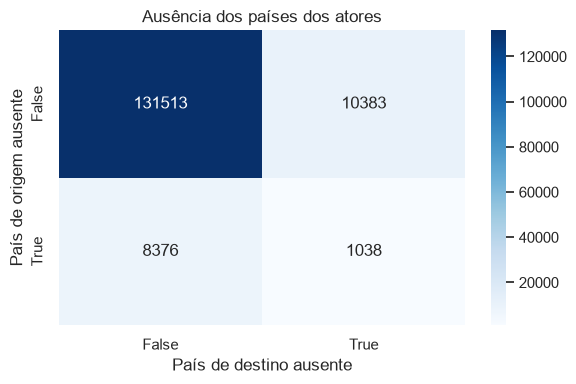

In [14]:
# [IA] Codex – Ele apenas gerou o código do gráfico que eu sugeri para ele.
ausencias_paises = pd.crosstab(
    df["Source Country"].isna(),
    df["Target Country"].isna(),
)

plt.figure(figsize=(6, 4))
sns.heatmap(ausencias_paises, annot=True, fmt="d", cmap="Blues")
plt.title("Ausência dos países dos atores")
plt.xlabel("País de destino ausente")
plt.ylabel("País de origem ausente")
plt.tight_layout()
plt.show()

## 3. Distribuição dos dados

### Estatísticas da intensidade

In [15]:
descricao_antes = df["Intensity"].describe()

descricao_antes

count    151310.0
mean     0.200599
std      4.455405
min         -10.0
25%          -2.0
50%           1.0
75%           3.0
max          10.0
Name: Intensity, dtype: Float64

### Resumo das categorias

In [16]:
colunas_categoricas = [
    "Source Name", "Target Name", "Source Country",
    "Target Country", "Country", "Event Text", "CAMEO Code", "Publisher",
]

df[colunas_categoricas].describe()

,Source Name,Target Name,Source Country,Target Country,Country,Event Text,CAMEO Code,Publisher
count,151310,151310,141896,139889,151290,151310,151310,151310
unique,10103,9366,219,213,211,241,241,45
top,United States,United States,United States,United States,Bosnia and Herzegovina,Make statement,010,Reuters News
freq,3561,3924,12473,10245,10110,26118,26118,74321


### Histograma da intensidade

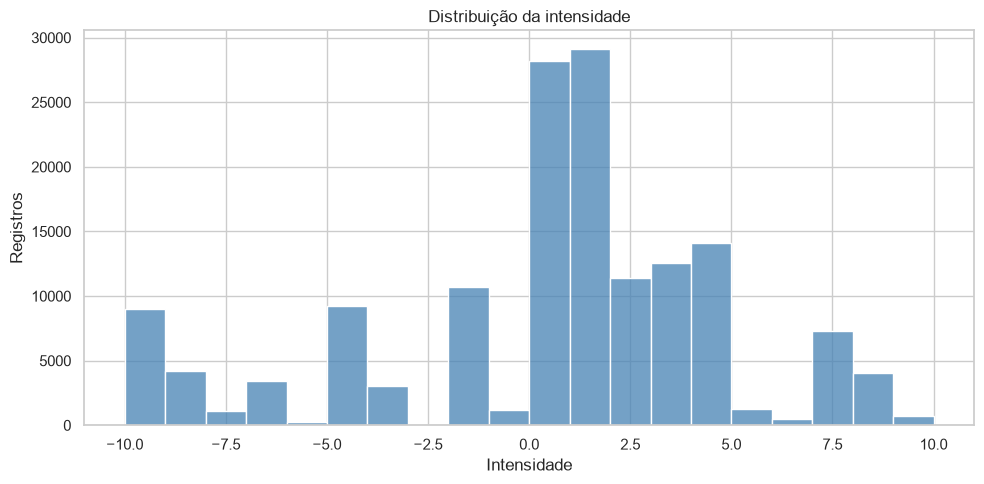

In [17]:
# [IA] Codex – Ele apenas gerou o código do gráfico que eu sugeri para ele.
plt.figure(figsize=(10, 5))
sns.histplot(data=df, x="Intensity", bins=20, color="steelblue")
plt.title("Distribuição da intensidade")
plt.xlabel("Intensidade")
plt.ylabel("Registros")
plt.tight_layout()
plt.show()

### Boxplot da intensidade

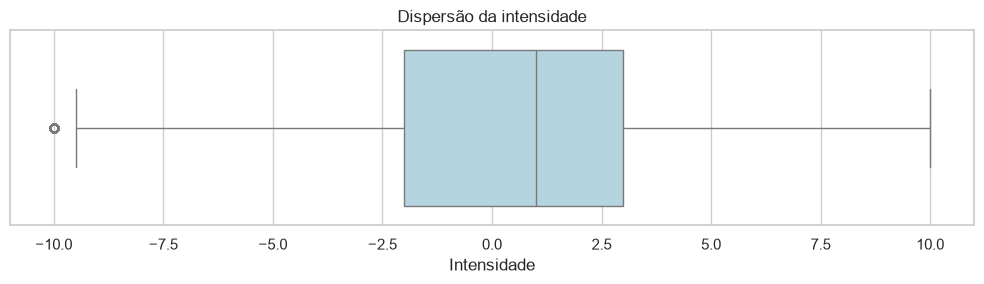

In [18]:
# [IA] Codex – Ele apenas gerou o código do gráfico que eu sugeri para ele.
plt.figure(figsize=(10, 3))
sns.boxplot(data=df, x="Intensity", color="lightblue")
plt.title("Dispersão da intensidade")
plt.xlabel("Intensidade")
plt.tight_layout()
plt.show()

### Média e mediana

In [19]:
df["Intensity"].agg(["mean", "median", "std", "var"])

mean       0.200599
median     1.000000
std        4.455405
var       19.850634
Name: Intensity, dtype: float64

### Ações mais frequentes

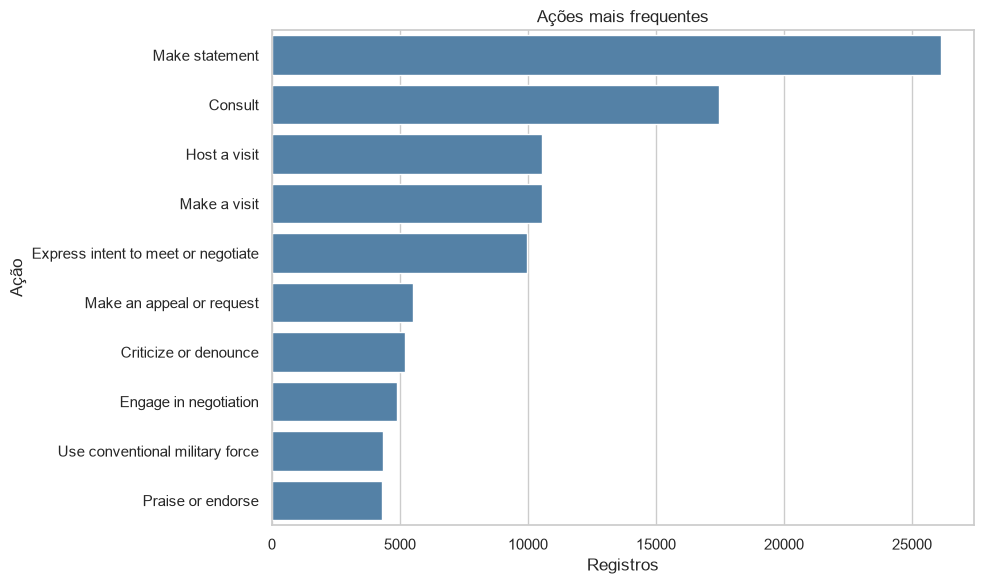

In [20]:
# [IA] Codex – Ele apenas gerou o código do gráfico que eu sugeri para ele.
acoes = df["Event Text"].value_counts().head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x=acoes.values, y=acoes.index, color="steelblue")
plt.title("Ações mais frequentes")
plt.xlabel("Registros")
plt.ylabel("Ação")
plt.tight_layout()
plt.show()

### Frequência dos códigos CAMEO

In [21]:
pd.DataFrame({
    "registros": df["CAMEO Code"].value_counts(),
    "percentual": df["CAMEO Code"].value_counts(normalize=True) * 100,
}).head(10).round(2)

,registros,percentual
CAMEO Code,,
010,26118,17.26
040,17465,11.54
043,10538,6.96
042,10531,6.96
036,9953,6.58
020,5529,3.65
111,5197,3.43
046,4903,3.24
190,4330,2.86


## 4. Tratamento dos dados

### Limpeza dos textos

In [22]:
for coluna in df.select_dtypes(include=["string", "object"]).columns:
    df[coluna] = df[coluna].str.strip()
    df[coluna] = df[coluna].replace("", pd.NA)

### Remoção de duplicatas exatas

In [23]:
linhas_antes = len(df)

df = df.loc[~duplicadas].copy()

print("Linhas antes:", linhas_antes)
print("Linhas depois:", len(df))
print("Linhas removidas:", linhas_antes - len(df))

Linhas antes: 151310
Linhas depois: 151310
Linhas removidas: 0


### Validação das coordenadas

In [24]:
pd.Series({
    "latitudes inválidas": (
        df["Latitude"].notna() & ~df["Latitude"].between(-90, 90)
    ).sum(),
    "longitudes inválidas": (
        df["Longitude"].notna() & ~df["Longitude"].between(-180, 180)
    ).sum(),
})

latitudes inválidas     0
longitudes inválidas    0
dtype: int64

In [25]:
df.loc[~df["Latitude"].between(-90, 90), "Latitude"] = pd.NA
df.loc[~df["Longitude"].between(-180, 180), "Longitude"] = pd.NA

### Valores extremos da intensidade

In [26]:
q1 = df["Intensity"].quantile(0.25)
q3 = df["Intensity"].quantile(0.75)
iqr = q3 - q1

limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

extremos = df["Intensity"].lt(limite_inferior) | df["Intensity"].gt(limite_superior)

df.loc[extremos, ["CAMEO Code", "Event Text", "Intensity"]].head(10)

,CAMEO Code,Event Text,Intensity
5,193,fight with small arms and light weapons,-10.0
16,190,Use conventional military force,-10.0
17,190,Use conventional military force,-10.0
27,190,Use conventional military force,-10.0
29,190,Use conventional military force,-10.0
40,190,Use conventional military force,-10.0
41,190,Use conventional military force,-10.0
47,190,Use conventional military force,-10.0
48,190,Use conventional military force,-10.0
51,190,Use conventional military force,-10.0


### Comparação das estatísticas

In [27]:
pd.DataFrame({
    "antes": descricao_antes,
    "depois": df["Intensity"].describe(),
}).round(2)

,antes,depois
count,151310.0,151310.0
mean,0.2,0.2
std,4.46,4.46
min,-10.0,-10.0
25%,-2.0,-2.0
50%,1.0,1.0
75%,3.0,3.0
max,10.0,10.0


### Comparação dos valores ausentes

In [28]:
pd.DataFrame({
    "antes": nulos_antes["quantidade"],
    "depois": df.isna().sum(),
})

,antes,depois
Event ID,0,0
Event Date,0,0
Source Name,0,0
Source Sectors,37880,37880
Source Country,9414,9414
Event Text,0,0
CAMEO Code,0,0
Intensity,0,0
Target Name,0,0
Target Sectors,53788,53788


## 5. Relações e evolução dos registros

In [29]:
colunas_correlacao = [
    "Intensity",
    "Latitude",
    "Longitude",
    "Sentence Number",
]

correlacao_pearson = df[colunas_correlacao].corr(method="pearson")

print("Correlação de Pearson entre as colunas numéricas")
correlacao_pearson.round(3)

Correlação de Pearson entre as colunas numéricas


,Intensity,Latitude,Longitude,Sentence Number
Intensity,1.000,0.060,-0.034,0.025
Latitude,0.060,1.000,-0.121,-0.004
Longitude,-0.034,-0.121,1.000,0.026
Sentence Number,0.025,-0.004,0.026,1.000


### Registros por mês

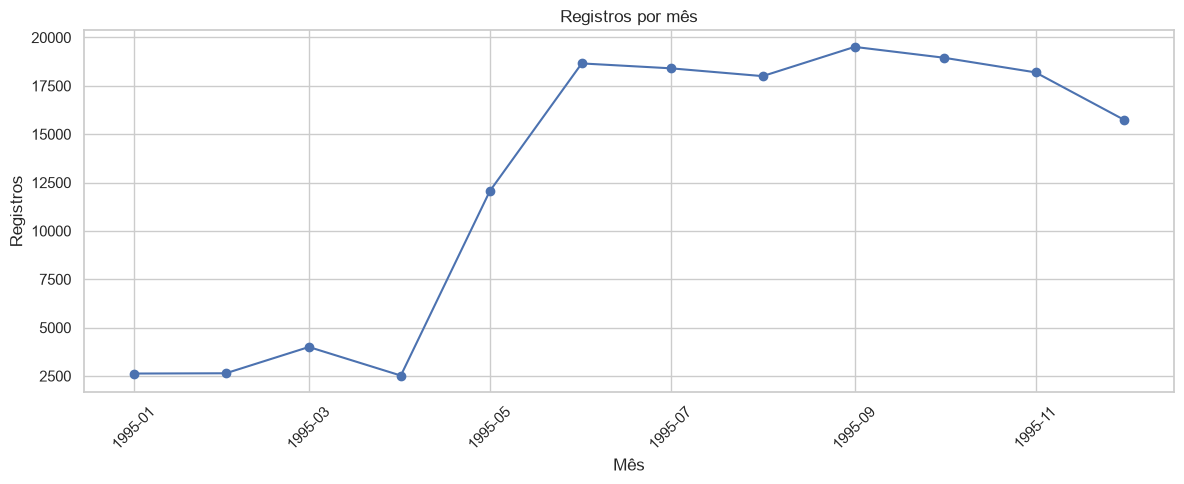

In [30]:
# [IA] Codex – Ele apenas gerou o código do gráfico que eu sugeri para ele.
df["mes"] = df["Event Date"].dt.to_period("M")
registros_mes = df.groupby("mes").size()

plt.figure(figsize=(12, 5))
plt.plot(registros_mes.index.to_timestamp(), registros_mes.values, marker="o")
plt.title("Registros por mês")
plt.xlabel("Mês")
plt.ylabel("Registros")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Resumo por ano

In [31]:
df.groupby(df["Event Date"].dt.year).agg(
    registros=("Event ID", "size"),
    noticias=("Story ID", "nunique"),
    veiculos=("Publisher", "nunique"),
)

,registros,noticias,veiculos
Event Date,,,
1995,151310,70374,45


### Países de origem e destino

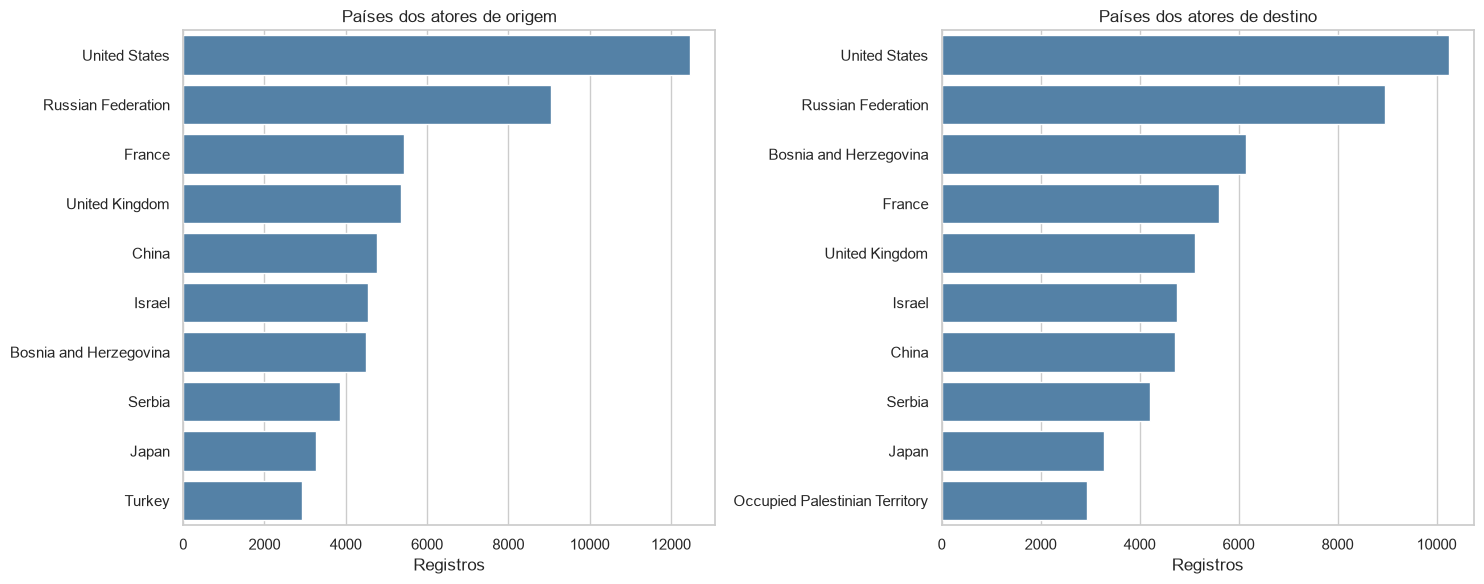

In [32]:
# [IA] Codex – Ele apenas gerou o código do gráfico que eu sugeri para ele.
paises_origem = df["Source Country"].value_counts().head(10)
paises_destino = df["Target Country"].value_counts().head(10)

fig, eixos = plt.subplots(1, 2, figsize=(15, 6))

sns.barplot(x=paises_origem.values, y=paises_origem.index, ax=eixos[0], color="steelblue")
eixos[0].set_title("Países dos atores de origem")
eixos[0].set_xlabel("Registros")
eixos[0].set_ylabel("")

sns.barplot(x=paises_destino.values, y=paises_destino.index, ax=eixos[1], color="steelblue")
eixos[1].set_title("Países dos atores de destino")
eixos[1].set_xlabel("Registros")
eixos[1].set_ylabel("")

plt.tight_layout()
plt.show()

### Países de localização dos eventos

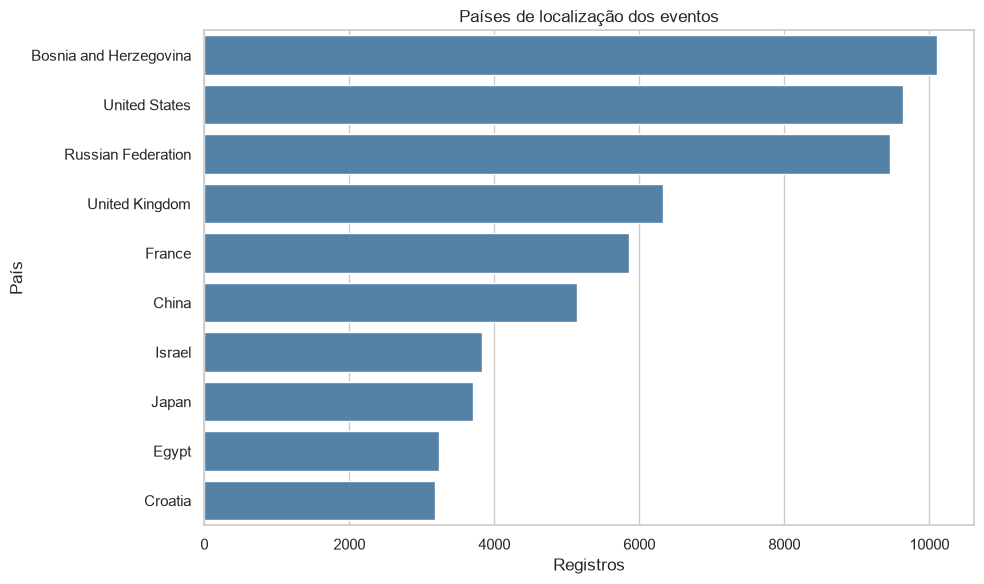

In [33]:
# [IA] Codex – Ele apenas gerou o código do gráfico que eu sugeri para ele.
locais = df["Country"].value_counts().head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x=locais.values, y=locais.index, color="steelblue")
plt.title("Países de localização dos eventos")
plt.xlabel("Registros")
plt.ylabel("País")
plt.tight_layout()
plt.show()

### Interações entre países

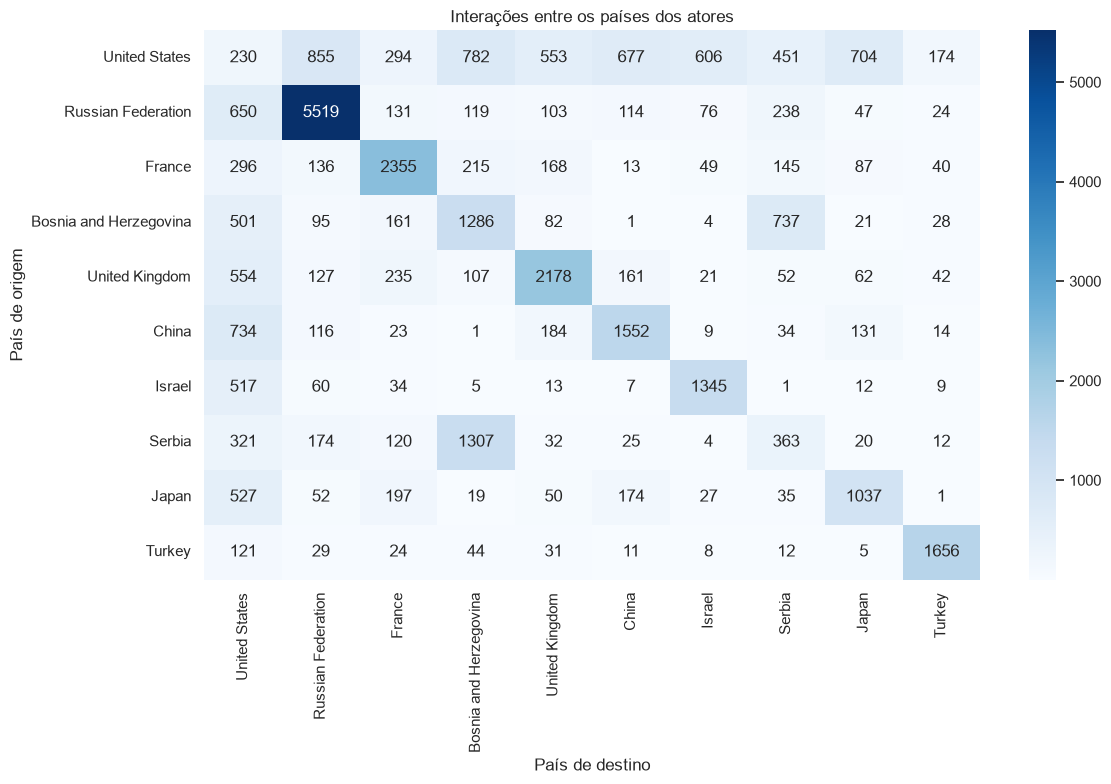

In [34]:
# [IA] Codex – Ele apenas gerou o código do gráfico que eu sugeri para ele.
paises = pd.concat([df["Source Country"], df["Target Country"]])
paises_principais = paises.value_counts().head(10).index

interacoes = pd.crosstab(df["Source Country"], df["Target Country"])
interacoes = interacoes.reindex(
    index=paises_principais,
    columns=paises_principais,
    fill_value=0,
)

plt.figure(figsize=(12, 8))
sns.heatmap(interacoes, annot=True, fmt="d", cmap="Blues")
plt.title("Interações entre os países dos atores")
plt.xlabel("País de destino")
plt.ylabel("País de origem")
plt.tight_layout()
plt.show()

### Intensidade por família CAMEO

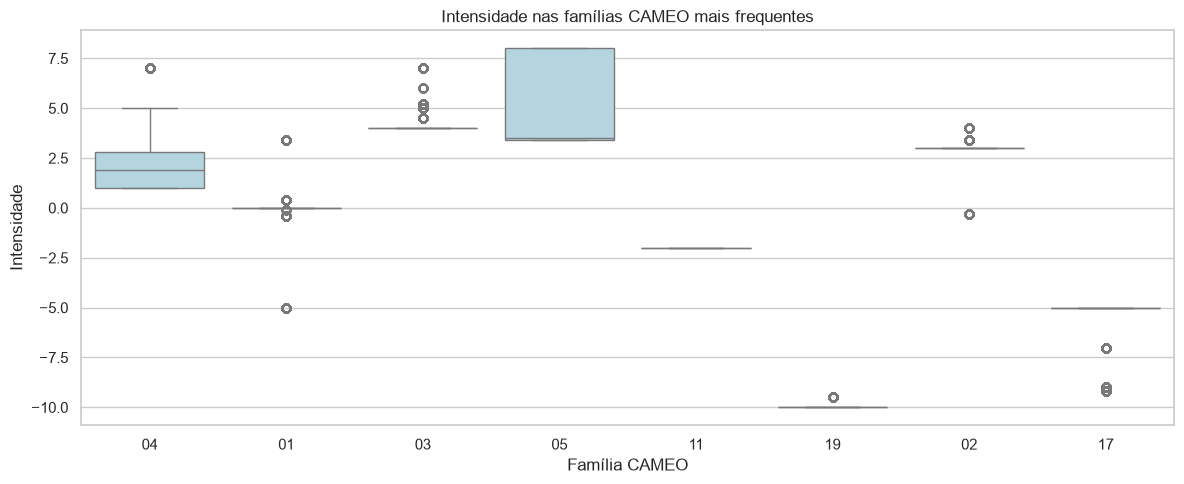

In [35]:
# [IA] Codex – Ele apenas gerou o código do gráfico que eu sugeri para ele.
df["familia_cameo"] = df["CAMEO Code"].str[:2]
familias = df["familia_cameo"].value_counts().head(8).index

plt.figure(figsize=(12, 5))
sns.boxplot(
    data=df[df["familia_cameo"].isin(familias)],
    x="familia_cameo",
    y="Intensity",
    order=familias,
    color="lightblue",
)
plt.title("Intensidade nas famílias CAMEO mais frequentes")
plt.xlabel("Família CAMEO")
plt.ylabel("Intensidade")
plt.tight_layout()
plt.show()

### Veículos de publicação

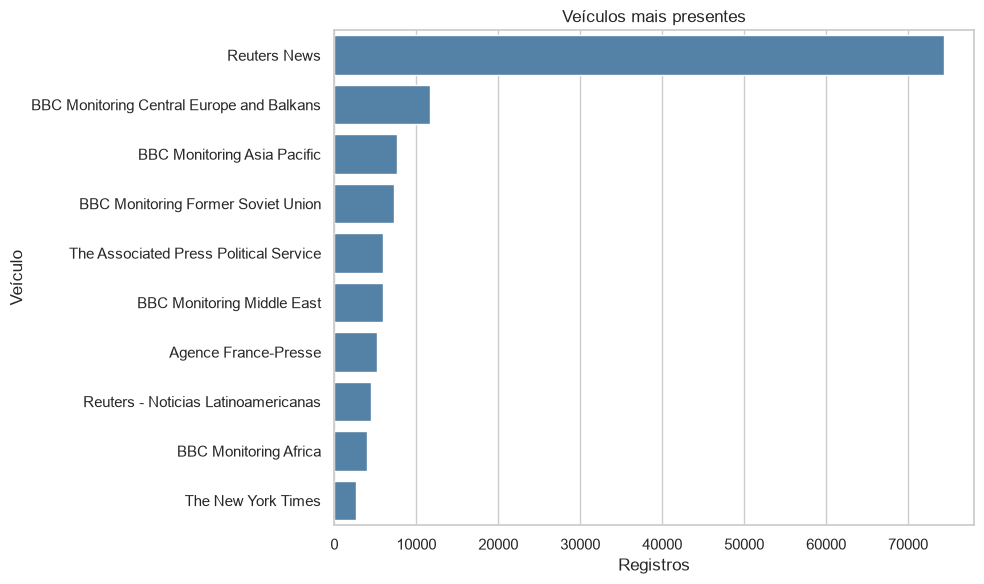

In [36]:
# [IA] Codex – Ele apenas gerou o código do gráfico que eu sugeri para ele.
veiculos = df["Publisher"].value_counts().head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x=veiculos.values, y=veiculos.index, color="steelblue")
plt.title("Veículos mais presentes")
plt.xlabel("Registros")
plt.ylabel("Veículo")
plt.tight_layout()
plt.show()

### Participação dos principais veículos

In [37]:
participacao_veiculos = df["Publisher"].value_counts() / len(df) * 100

participacao_veiculos.head(10).round(2)

Publisher
Reuters News                                 49.12
BBC Monitoring Central Europe and Balkans     7.71
BBC Monitoring Asia Pacific                   5.09
BBC Monitoring Former Soviet Union            4.84
The Associated Press Political Service        3.92
BBC Monitoring Middle East                    3.91
Agence France-Presse                          3.44
Reuters - Noticias Latinoamericanas           2.95
BBC Monitoring Africa                         2.65
The New York Times                            1.71
Name: count, dtype: Float64

### Atores mais frequentes

In [38]:
df["Source Name"].value_counts().head(10)

Source Name
United States                         3561
Bill Clinton                          2030
United Nations                        1979
Warren Christopher                    1967
China                                 1768
Russia                                1691
Serbia                                1487
North Atlantic Treaty Organization    1440
France                                1392
Bosnia and Herzegovina                1341
Name: count, dtype: Int64

### Atores de destino mais frequentes

In [39]:
df["Target Name"].value_counts().head(10)

Target Name
United States             3924
Bosnia and Herzegovina    3565
Russia                    2617
United Nations            2461
France                    2312
China                     2268
Serbia                    2081
Israel                    1949
Unspecified Actor         1916
United Kingdom            1587
Name: count, dtype: Int64

## 6. Preparação dos dados para o grafo

### Eventos com atores e data identificados

In [40]:
eventos_grafo = df.dropna(subset=["Source Name", "Target Name", "Event Date"])
eventos_grafo = eventos_grafo[[
    "Source Name", "Source Country", "Target Name", "Target Country",
    "Event Date", "mes", "CAMEO Code", "Intensity", "arquivo_origem",
]].copy()

print("Registros disponíveis:", len(df))
print("Registros para o grafo:", len(eventos_grafo))
print("Registros sem os campos necessários:", len(df) - len(eventos_grafo))

eventos_grafo.head()

Registros disponíveis: 151310
Registros para o grafo: 151310
Registros sem os campos necessários: 0


,Source Name,Source Country,Target Name,Target Country,Event Date,mes,CAMEO Code,Intensity,arquivo_origem
0,Extremist (Russia),Russian Federation,Boris Yeltsin,Russian Federation,1995-01-01,1995-01,051,3.4,eventos_1995.tab
1,Government (Bosnia and Herzegovina),Bosnia and Herzegovina,Citizen (Serbia),Serbia,1995-01-01,1995-01,030,4.0,eventos_1995.tab
2,Citizen (Serbia),Serbia,Government (Bosnia and Herzegovina),Bosnia and Herzegovina,1995-01-01,1995-01,030,4.0,eventos_1995.tab
3,Canada,Canada,City Mayor (Canada),Canada,1995-01-01,1995-01,051,3.4,eventos_1995.tab
4,Lawyer/Attorney (Canada),Canada,Police (Canada),Canada,1995-01-01,1995-01,173,-5.0,eventos_1995.tab


### Arestas por par de atores e mês

In [41]:
arestas = eventos_grafo.groupby(
    ["Source Name", "Source Country", "Target Name", "Target Country", "mes"],
    dropna=False,
).size().reset_index(name="peso")

arestas.sort_values("peso", ascending=False).head(10)

,Source Name,Source Country,Target Name,Target Country,mes,peso
61209,North Atlantic Treaty Organization,<NA>,Bosnia and Herzegovina,Bosnia and Herzegovina,1995-09,184
61234,North Atlantic Treaty Organization,<NA>,Citizen (Serbia),Serbia,1995-09,182
61369,North Atlantic Treaty Organization,<NA>,Serbia,Serbia,1995-09,124
74304,Serbia,Serbia,Bosnia and Herzegovina,Bosnia and Herzegovina,1995-07,107
7320,Bill Clinton,United States,Japan,Japan,1995-11,105
74306,Serbia,Serbia,Bosnia and Herzegovina,Bosnia and Herzegovina,1995-09,96
7537,Bill Clinton,United States,United Kingdom,United Kingdom,1995-11,91
48079,Lee Teng Hui,Taiwan,United States,United States,1995-06,88
75222,Shimon Peres,Israel,Yasir Arafat,Occupied Palestinian Territory,1995-09,82
83903,United States,United States,Lee Teng Hui,Taiwan,1995-06,79


### Conferência das contagens

In [42]:
print("Eventos utilizados:", len(eventos_grafo))
print("Soma dos pesos:", arestas["peso"].sum())
print("Arestas por mês:", len(arestas))

Eventos utilizados: 151310
Soma dos pesos: 151310
Arestas por mês: 88224


## Conclusão

Nessa análise exploratória, usamos o recorte de 1995 do ICEWS como piloto, somando 151.310 registros entre 01/01/1995 e 31/12/1995. Depois desse teste inicial, rodamos a mesma verificação para os 28 anos completos da base (1995 a 2022) com o script `resumir_anos.py`. Os números abaixo são do piloto de 1995, mas nos 28 anos as proporções mudam um pouco (o `District` vazio, por exemplo, sobe para cerca de 82% em média).

Sobre a qualidade da base em 1995, não encontramos nenhuma linha exatamente duplicada nos campos originais nem `Event ID` repetido. Já nos valores ausentes, o que mais chamou atenção foi `District`, vazio em 75,62% dos registros. Mesmo assim, optamos por não apagar essas linhas nem preencher os vazios de forma automática, já que a falta de um campo não inutiliza o resto da linha para outras análises.

Na coluna `Intensity`, a média ficou em 0,20 e a mediana em 1,00. O cálculo pelo IQR chegou a apontar valores extremos (como -10), mas decidimos mantê-los. Na escala CAMEO, essa pontuação vem direto do tipo de ação, então um -10 em eventos de combate militar não é erro de preenchimento, e sim o comportamento esperado da variável.

Olhando a distribuição dos eventos, a ação mais frequente foi `Make statement`, com 26.118 registros (17,26% do total). Também ficou clara uma concentração forte nas fontes: só a `Reuters News` responde por 49,12% da base de 1995. Esse peso de um único veículo precisa ser levado em conta na hora de interpretar rankings e a evolução mês a mês.

Na preparação inicial do grafo, testamos no piloto de 1995 um primeiro modelo agrupado por par de atores (junto com os países) e mês. Todos os 151.310 registros tinham os dois atores e a data preenchidos, gerando 88.224 arestas com peso igual à contagem de eventos. Para o projeto final, porém, mudamos essa modelagem: trocamos os nós de atores para países, juntamos os 28 anos sem corte mensal e passamos a usar a média da intensidade como peso das arestas (por isso o grafo final também tem pesos negativos). Com isso, evitamos a fragmentação de milhares de atores e homônimos, conseguimos enxergar as relações entre países no período inteiro e ainda diferenciamos cooperação de conflito, chegando a 250 países e 29.381 arestas.

Quando revisamos os nomes dos países para montar esse grafo, achamos alguns problemas reais de padronização, como a Macedônia aparecendo com dois nomes diferentes e erro de codificação em `"CuraÃ§ao"`. Já resolvemos e unificamos esses casos no `gerar_arestas.py`, deixando tudo registrado no `paises_padronizados.csv`.

Também precisamos levar em conta algumas limitações da própria base. Como os registros são extraídos automaticamente de notícias, os dados dependem muito do que a imprensa cobriu, além de estarem sujeitos a erros do extrator e a relatos repetidos do mesmo acontecimento. Na prática, essas contagens mostram o que foi noticiado e capturado pelo sistema, e não necessariamente a frequência real dos fatos políticos. Para detalhes mais específicos de códigos e regras, seguimos conferindo direto nos manuais oficiais do ICEWS e do CAMEO.

## Dados ausentes e possibilidades de enriquecimento

Olhando mais de perto o recorte piloto de 1995 (151.310 registros), os dados faltantes se concentram basicamente em dois grupos: a classificação dos atores e a localização dos eventos. Em vez de sair excluindo qualquer linha com campo vazio, a ideia aqui é entender o impacto desses nulos, ver qual mecanismo de ausência faz mais sentido em cada caso e decidir como lidar com eles conforme a pergunta que quisermos responder.

### Países e setores dos atores

Nos campos de setor, `Source Sectors` está vazio em 37.880 linhas (25,03%) e `Target Sectors` em 53.788 (35,55%). Como um mesmo ator pode ter mais de um setor, o valor nulo só indica que essa classificação não veio preenchida naquele registro. Já nos países ligados aos atores, `Source Country` tem 9.414 nulos (6,22%) e `Target Country` tem 11.421 (7,55%). Essas colunas apontam a nacionalidade ou o vínculo do ator, diferente de `Country`, que indica onde o evento aconteceu.

Pelos padrões que vimos nos dados e pelo heatmap de correlação entre ausências, não dá para tratar esses nulos como **MCAR** (totalmente aleatórios). A falta de informação tem relação clara com características que aparecem na própria tabela, como o tipo de ator: organizações internacionais (ONU, OTAN) e atores genéricos muitas vezes não têm um país vinculado, enquanto países citados de forma genérica costumam vir sem setor preenchido. Isso puxa bem mais para **MAR** (a ausência depende de outras variáveis observadas), podendo ter também um pouco de **MNAR** quando a própria notícia não informa o setor/vínculo ou o extrator não consegue capturar aquele perfil.

Preencher esses quatro campos na mão ou via script é bem complicado. Para fazer isso direito, precisaríamos ter certeza de quem é o ator e de qual era o papel dele exatamente na data do evento. O problema é que existem homônimos, pessoas que mudaram de cargo ou setor ao longo do tempo e organizações internacionais que não pertencem a um único país. Por isso, não faz sentido jogar o país da sede para uma organização internacional nem copiar a classificação de outro registro só porque o nome é parecido.

Por enquanto, o mais seguro é manter esses nulos como estão. Se quisermos comparar países de origem e destino em 1995, ainda sobram 131.513 registros completos. Para comparar setores, ficamos com 77.565. Agora, se exigíssemos os quatro campos preenchidos ao mesmo tempo, a base cairia para 66.719 linhas (uma perda de 55,91%), o que já começaria a distorcer bastante o peso dos atores nos dados.

### Localização dos eventos

Nos dados geográficos de 1995, as ausências maiores estão nos níveis mais detalhados: `District` falta em 114.421 linhas (75,62%), `City` em 28.743 (19,00%) e `Province` em 13.535 (8,95%). Já os campos mais gerais quase não têm falhas: `Country`, `Latitude` e `Longitude` têm apenas 20 registros vazios cada (cerca de 0,013%).

Aqui também descartamos **MCAR**. O heatmap de correlação entre ausências mostra que essas colunas falham de forma ligada entre si: `Country`, `Latitude` e `Longitude` somem juntas, e a presença de `District` e `City` varia muito dependendo do país, da divisão administrativa local e do quanto a notícia detalhou o local. Ou seja, o comportamento encaixa principalmente em **MAR**, com um possível componente **MNAR** nos casos em que a própria notícia omite o local exato ou o evento acontece em regiões com cobertura menos detalhada.

O ponto principal aqui é que faltar uma divisão mais específica não deixa o evento sem localização. Muitas linhas sem cidade ou distrito continuam tendo província, país e coordenadas válidas. Então o melhor caminho é trabalhar na escala geográfica disponível para cada pergunta. Se filtrássemos exigindo cidade, distrito, província e país preenchidos juntos, sobrariam só 36.424 registros, jogando fora 75,93% da base.

Diferente dos dados dos atores, na parte geográfica vemos mais espaço para enriquecimento quando existem coordenadas preenchidas. Daria para cruzar `Latitude` e `Longitude` com bases cartográficas e limites territoriais para tentar recuperar país e província primeiro, e depois avaliar se há precisão suficiente para chegar em cidade ou distrito. Mesmo assim, não dá para preencher direto sem checar a qualidade dessas coordenadas. Em alguns casos, o ponto marcado pode ser só o centro geográfico de uma região ou país, e não o lugar exato do acontecimento (ou seja, a cidade mais próxima do ponto não é necessariamente onde o evento ocorreu). Além disso, nomes e fronteiras administrativas podem ter mudado de 1995 para cá.

### Decisão de tratamento

A decisão do grupo nesta etapa é manter a base principal intacta, preservando os valores originais e os nulos. Quando alguma análise depender de campos específicos, filtramos apenas os registros completos para aquela consulta e deixamos registrado quanto da base ficou de fora. Também descartamos preenchimentos genéricos, como usar o valor mais frequente para países/setores ou trocar coordenadas vazias por zero, já que 0 é uma coordenada geográfica válida e distorceria os dados.

Se decidirmos fazer algum enriquecimento mais para frente, o plano é salvar os valores recuperados em colunas separadas, anotando a fonte, o critério usado e o nível de confiança. Assim fica fácil diferenciar o dado original do que foi inferido depois, mantendo como vazio o que não tiver respaldo. Por enquanto, deixamos isso apenas mapeado e nenhum preenchimento foi aplicado nesta etapa.